# 03 · 가장 좋은 행동열 찾기 — 최적화

> 비용이 가장 작은 입력열을 찾는 일이 최적화다. 기울기를 따라 내려가는 경사하강은 강력하지만, 출발점에 따라 다른 골짜기에 갇히고 기울기가 0인 곳에서는 아무것도 보지 못한다.

**지금 위치**

01 상태·입력·모델 → 02 비용 → **03 최적화** → 04 MPC → 05~07 MPPI → 08~09 로봇팔 → 10~13 프로젝트

**이 노트를 끝내면**
1. "비용 지형"을 그림으로 보고, 최적화가 그 지형에서 가장 낮은 곳을 찾는 일임을 설명할 수 있다.
2. 격자 탐색이 왜 금방 불가능해지는지 계산할 수 있다.
3. 수치 미분과 경사하강을 직접 구현하고, 학습률의 효과를 설명할 수 있다.
4. 국소 최솟값과 "기울기가 0이라 안 보이는" 비용이라는 경사하강의 두 가지 한계를 예로 들 수 있다.

**필요한 것:** [01](01_state_input_model.ipynb)의 rollout, [02](02_cost_function.ipynb)의 `cart_cost` · **예상 시간:** 40분

## 복습 퀴즈 (02)

<details><summary>1. 비용 함수에 노력 항(u²)이 없으면 어떤 후보가 뽑힐 위험이 있나?</summary>

입력을 크고 들쭉날쭉하게 써서라도 목표에 조금 더 빨리 가는 후보.
</details>

<details><summary>2. 최종(terminal) 비용은 무엇을 대신 보는 장치인가?</summary>

horizon이 끝난 뒤의 미래. 끝에 목표에 멈춰 있으면 그 뒤에도 거기 있을 것이라고 보고 끝 상태에 비용을 매긴다.
</details>

<details><summary>3. soft 제약의 뜻은?</summary>

규칙을 어긴 만큼 비용을 주는 방식. 어기면 손해지만, 다른 이득이 크면 어길 수도 있다.
</details>

In [1]:
import time
import numpy as np
from common import setup_plot
from course import cart_rollout, cart_cost      # 01, 02에서 만든 코드
plt = setup_plot()
x0 = np.array([0.0, 0.0])

## 1. 문제 — 입력열은 무한히 많다

02에서는 사람이 만든 후보 몇 개를 비교했다. 하지만 horizon이 30스텝이면 입력열은 숫자 30개이고, 각각 아무 실수나 될 수 있다. 가능한 입력열은 무한히 많다. 사람이 후보를 만들어 줄 수도 없다.

그래서 비용 $J(U)$가 가장 작아지는 $U$를 **컴퓨터가 체계적으로 찾게** 해야 한다. 이 일을 **최적화**(optimization)라고 하고, 답을 $U^* = \arg\min_U J(U)$로 쓴다. "J를 가장 작게 만드는 U"라는 뜻이다.

## 2. 비용 지형 — 입력이 2개뿐이라면

### 아이디어
입력이 30개면 그림으로 볼 수 없다. 그래서 문제를 아주 작게 줄인다.

- horizon $T=2$, 시간 간격 $\Delta t = 1$초. 입력은 $u_0, u_1$ 두 개뿐이다.
- 목표: **2초 뒤 1 m에 멈춰 있기.** 비용은 02의 `cart_cost`에서 최종 위치·속도 항과 작은 노력 항만 쓴다.

입력이 두 개면 $(u_0, u_1)$ 평면의 모든 점에 비용이 하나씩 정해진다. 비용을 색(높이)으로 칠하면 산과 골짜기가 있는 **지도**가 된다. 이것을 **비용 지형**(cost landscape)이라 부른다. 최적화는 이 지형에서 **가장 낮은 곳을 찾는 일**이다.

손으로 풀어 보면: $p_2 = 1.5u_0 + 0.5u_1$, $v_2 = u_0 + u_1$이다. 멈추려면 $u_1 = -u_0$이고, 그러면 $p_2 = u_0 = 1$이다. 정답은 $(u_0, u_1) = (1, -1)$ 근처다(노력 항 때문에 아주 조금 다를 수 있다).

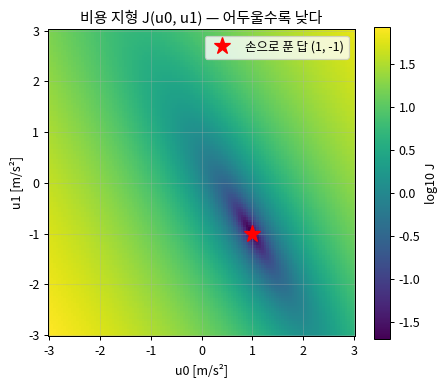

In [2]:
def J2(U):
    # 입력 2개짜리 문제: 2초 뒤 1 m에 멈춰 있기 (U[..., 2] -> J[...])
    X = cart_rollout(x0, U, dt=1.0)
    return cart_cost(X, U, w_goal=0.0, w_u=0.01, w_term=1.0, w_vterm=1.0)

g = np.linspace(-3, 3, 121)
G0, G1 = np.meshgrid(g, g, indexing='ij')
J_grid = J2(np.stack([G0, G1], axis=-1))          # [121, 121] 모든 점의 비용 한 번에

def draw_landscape(ax, J_grid, title):
    m = ax.pcolormesh(G0, G1, np.log10(J_grid), shading='auto', cmap='viridis')
    plt.colorbar(m, ax=ax, label='log10 J')
    ax.set_xlabel('u0 [m/s²]'); ax.set_ylabel('u1 [m/s²]'); ax.set_title(title); ax.set_aspect('equal')

fig, ax = plt.subplots(figsize=(5.5, 4.5))
draw_landscape(ax, J_grid, '비용 지형 J(u0, u1) — 어두울수록 낮다')
ax.plot(1, -1, 'r*', ms=14, label='손으로 푼 답 (1, -1)'); ax.legend()
plt.show()

**결과 해석:** 어두운 골짜기가 대각선으로 길게 뻗어 있고, 가장 어두운 곳이 (1, −1) 근처다. 골짜기가 길쭉하다는 것은 "$u_0$를 키우고 $u_1$을 그만큼 줄이는" 방향으로는 비용이 천천히 변하고, 그와 수직인 방향으로는 급하게 변한다는 뜻이다. 이 모양은 5절에서 다시 중요해진다.

## 3. 첫 번째 방법 — 격자 탐색

### 아이디어
가장 단순한 방법은 위 그림을 그린 것처럼 **모든 격자점의 비용을 계산하고 가장 작은 것을 고르는 것**이다.

In [3]:
i, j = np.unravel_index(J_grid.argmin(), J_grid.shape)
print('격자 탐색: 비용 계산 %d번, 최적 (u0, u1) = (%.2f, %.2f), J = %.4f' % (J_grid.size, g[i], g[j], J_grid.min()))

격자 탐색: 비용 계산 14641번, 최적 (u0, u1) = (1.00, -1.00), J = 0.0200


입력 2개, 한 축에 121칸이면 계산 14,641번으로 답을 찾는다. 그러면 입력이 20개라면?

**예측해 보기:** 입력 20개를 한 축에 10칸씩만 나눠도 비용 계산은 몇 번일까? 1초에 10억 번 계산한다면 얼마나 걸릴까?

In [4]:
for T in [2, 5, 10, 20, 30]:
    n = 10.0 ** T                     # 한 축 10칸
    seconds = n / 1e9                 # 1초에 10억 번
    print('입력 %2d개: 계산 %.0e번, 약 %.1e초 (%.1e년)' % (T, n, seconds, seconds / 3.15e7))

입력  2개: 계산 1e+02번, 약 1.0e-07초 (3.2e-15년)
입력  5개: 계산 1e+05번, 약 1.0e-04초 (3.2e-12년)
입력 10개: 계산 1e+10번, 약 1.0e+01초 (3.2e-07년)
입력 20개: 계산 1e+20번, 약 1.0e+11초 (3.2e+03년)
입력 30개: 계산 1e+30번, 약 1.0e+21초 (3.2e+13년)


**결과 해석:** 입력이 20개면 $10^{20}$번이고, 1초에 10억 번 계산해도 3,000년이 넘게 걸린다. 차원이 늘 때마다 개수가 곱으로 불어나는 이 현상을 **차원의 저주**(curse of dimensionality)라 한다. 격자 탐색은 입력이 몇 개일 때만 쓸 수 있다. 로봇팔은 관절 7개 × 30스텝 = 210개다.

모든 곳을 보지 않고, **지금 있는 곳에서 어느 쪽이 내리막인지**만 보고 내려가는 방법이 필요하다.

## 4. 기울기 — 어느 쪽이 내리막인가 (입력 1개)

### 아이디어
안개 낀 산에서 길을 잃었다고 하자. 주변이 안 보여도 발밑이 어느 쪽으로 기울었는지는 알 수 있다. 내리막 쪽으로 한 걸음씩 가면 결국 골짜기에 닿는다.

입력이 하나인 함수 $f(u) = (u-1)^2$로 먼저 연습하자. 최솟값은 $u=1$이다.
- **기울기**(gradient, 미분) $f'(u)$: $u$를 조금 늘렸을 때 $f$가 얼마나 변하는지의 비율.
- 기울기가 양수면 오른쪽이 오르막이다. 그러니 왼쪽(−)으로 간다. 음수면 오른쪽(+)으로 간다.
- 그래서 한 걸음은 $u \leftarrow u - \alpha f'(u)$다. $\alpha$는 보폭이며 **학습률**(learning rate, step size)이라 부른다.

이렇게 기울기 반대로 조금씩 내려가는 방법을 **경사하강**(gradient descent)이라 한다.

### 기울기를 숫자로 구하기
공식을 몰라도, $u$를 아주 조금($\varepsilon$) 양쪽으로 바꿔 비용 차이를 재면 된다.

$$
f'(u) \approx \frac{f(u+\varepsilon) - f(u-\varepsilon)}{2\varepsilon}
$$

이것을 **수치 미분**이라 한다. 입력이 여러 개면 입력마다 하나씩 바꿔 가며 같은 계산을 한다. 아래 `numerical_grad`는 `course.py`에 같은 코드로 저장해 두었다.

In [5]:
def numerical_grad(f, U, eps=1e-5):
    # f(U)의 기울기를 원소마다 중앙 차분으로 근사
    U = np.asarray(U, float)
    grad = np.zeros_like(U)
    for i in np.ndindex(U.shape):
        e = np.zeros_like(U); e[i] = eps
        grad[i] = (f(U + e) - f(U - e)) / (2 * eps)
    return grad

f = lambda u: (u[0] - 1.0) ** 2
print('u=3에서 수치 기울기 %.4f (정답 2(u-1) = 4)' % numerical_grad(f, np.array([3.0]))[0])

u=3에서 수치 기울기 4.0000 (정답 2(u-1) = 4)


**예측해 보기:** $u=3$에서 출발해 경사하강을 하면, 학습률 $\alpha$ = 0.1, 0.5, 1.05 중 어느 것이 가장 빨리 $u=1$에 갈까? 어느 것이 실패할까?

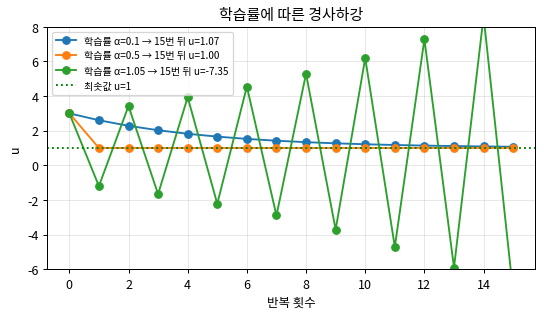

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for alpha in [0.1, 0.5, 1.05]:
    u = np.array([3.0]); path = [u[0]]
    for it in range(15):
        u = u - alpha * numerical_grad(f, u)
        path.append(u[0])
    ax.plot(path, 'o-', label=f'학습률 α={alpha} → 15번 뒤 u={path[-1]:.2f}')
ax.axhline(1.0, color='g', ls=':', label='최솟값 u=1')
ax.set_xlabel('반복 횟수'); ax.set_ylabel('u'); ax.set_ylim(-6, 8); ax.legend(fontsize=8)
ax.set_title('학습률에 따른 경사하강'); plt.show()

**결과 해석:**
- α=0.1: 매번 조금씩 내려가서 천천히 다가간다.
- α=0.5: 이 함수에서는 한 번에 정확히 도착한다(운이 좋은 경우).
- α=1.05: 보폭이 너무 커서 골짜기를 건너뛰고, 반대편으로 갈 때마다 더 멀어진다. 이것을 **발산**이라 한다.

학습률이 작으면 느리고 크면 발산한다. 적당한 값은 함수가 얼마나 가파른지에 달려 있다.

**한 문장으로:** 경사하강의 한 걸음을 "기울기"와 "학습률"이라는 말을 넣어 설명해 보자.

## 5. 입력 2개 지형에서 경사하강

이제 2절의 지형에서 (0, 0)부터 내려가 본다. 입력이 두 개면 기울기도 두 개(각 입력 방향의 기울기)이고, 두 방향으로 동시에 한 걸음 간다.

**예측해 보기:** 2절에서 골짜기가 길쭉했다. 학습률이 작을 때와 클 때 경로가 어떻게 다를까?

α=0.02 반복 50번 뒤 U=(0.569, -0.258), J=0.1765
α=0.1  반복 50번 뒤 U=(0.918, -0.860), J=0.02203
α=0.3  반복  5번 뒤 U=(3.617, 1.269), J=49.63


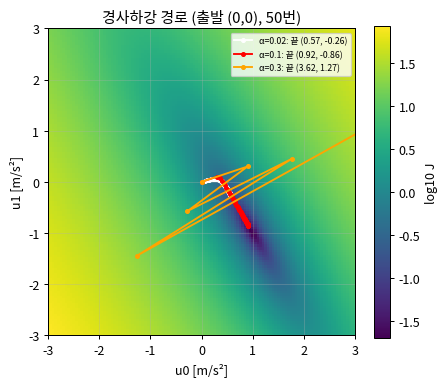

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
draw_landscape(ax, J_grid, '경사하강 경로 (출발 (0,0), 50번)')
for alpha, col in [(0.02, 'w'), (0.1, 'r'), (0.3, 'orange')]:
    U = np.zeros(2); path = [U.copy()]
    for it in range(50):
        U = U - alpha * numerical_grad(J2, U)
        path.append(U.copy())
        if np.abs(U).max() > 3: break                  # 그림 밖으로 나가면 중단
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], '.-', color=col, label=f'α={alpha}: 끝 ({U[0]:.2f}, {U[1]:.2f})')
    print('α=%-4s 반복 %2d번 뒤 U=(%.3f, %.3f), J=%.4g' % (alpha, len(path) - 1, U[0], U[1], J2(U)))
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.legend(fontsize=7, loc='upper right'); plt.show()

**결과 해석:**
- α=0.02: 방향은 맞지만 50번 안에 골짜기 바닥까지 못 간다.
- α=0.1: (1, −1) 가까이 도착한다.
- α=0.3: 가파른 방향(골짜기를 가로지르는 방향)으로 튕기며 커지다가 지형 밖으로 나간다(발산).

길쭉한 골짜기에서는 가파른 방향 때문에 학습률을 크게 할 수 없다. 그러면 완만한 방향(골짜기를 따라가는 방향)으로는 느리게 간다. 경사하강이 느려지는 흔한 이유다.

## 6. 진짜 크기의 문제 — 입력 20개

이제 01·02의 원래 문제로 돌아간다. $\Delta t = 0.1$초, $T=20$(2초), 기본 가중치의 `cart_cost`다. 그림으로 볼 수 없지만, 경사하강은 같은 방법으로 쓸 수 있다.

**계산을 빠르게:** `numerical_grad`는 입력마다 비용을 두 번씩 따로 계산하므로 입력 20개면 40번이다. 그런데 01에서 배운 대로 **후보 여러 개를 배열 하나로 한 번에** rollout할 수 있다. 입력 하나씩만 조금 바꾼 입력열 20개를 `+ε` 쪽과 `−ε` 쪽으로 쌓으면, 비용 계산 두 번(배열 두 개)으로 기울기 20개가 나온다. 결과는 `numerical_grad`와 같다.

In [8]:
def J20(U):
    return cart_cost(cart_rollout(x0, U), U)        # U[..., 20] -> J[...]

def grad_batch(f, U, eps=1e-5):
    # 입력을 하나씩 바꾼 T개의 입력열을 행으로 쌓아 한 번에 계산 (numerical_grad와 같은 값)
    E = np.eye(U.shape[-1]) * eps                   # [T, T]: k번째 행은 k번째 입력만 +eps
    return (f(U + E) - f(U - E)) / (2 * eps)

U_test = np.random.default_rng(0).normal(size=20)
print('두 방법의 기울기 최대 차이: %.2e' % np.abs(grad_batch(J20, U_test) - numerical_grad(J20, U_test)).max())

두 방법의 기울기 최대 차이: 0.00e+00


α=0.05 2000번 뒤 J=4.004, 끝 상태 p=1.01 m, v=-0.0251 m/s
α=0.2  2000번 뒤 J=4.002, 끝 상태 p=1.01 m, v=-0.0268 m/s
α=0.3  2000번 뒤 J=1.412e+23, 끝 상태 p=-9.51e+10 m, v=-8e+10 m/s


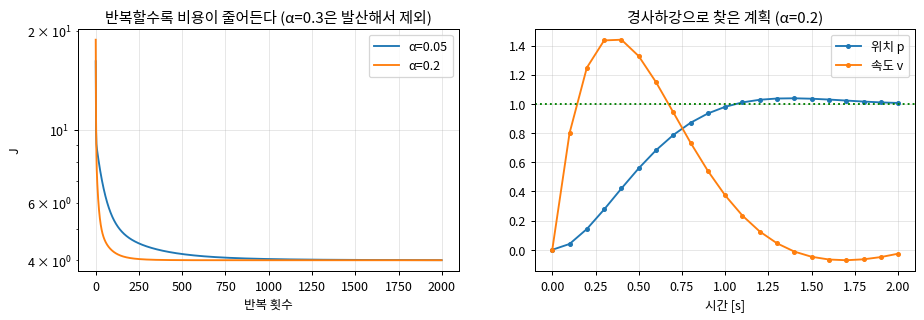

In [9]:
results = {}
for alpha in [0.05, 0.2, 0.3]:
    U = np.zeros(20); history = []
    for it in range(2000):
        U = U - alpha * grad_batch(J20, U)
        history.append(J20(U))
    results[alpha] = (U, np.array(history))
    X = cart_rollout(x0, U)
    print('α=%-4s 2000번 뒤 J=%.4g, 끝 상태 p=%.3g m, v=%.3g m/s' % (alpha, history[-1], X[-1, 0], X[-1, 1]))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for alpha in [0.05, 0.2]:
    axs[0].plot(results[alpha][1], label=f'α={alpha}')
axs[0].set_yscale('log'); axs[0].set_xlabel('반복 횟수'); axs[0].set_ylabel('J'); axs[0].legend()
axs[0].set_title('반복할수록 비용이 줄어든다 (α=0.3은 발산해서 제외)')
X = cart_rollout(x0, results[0.2][0])
axs[1].plot(np.arange(21) * 0.1, X[:, 0], '.-', label='위치 p')
axs[1].plot(np.arange(21) * 0.1, X[:, 1], '.-', label='속도 v')
axs[1].axhline(1.0, color='g', ls=':'); axs[1].set_xlabel('시간 [s]'); axs[1].legend()
axs[1].set_title('경사하강으로 찾은 계획 (α=0.2)'); plt.show()

**결과 해석:** α=0.2면 비용이 줄어들어 약 4.0에 수렴하고, 계획은 2초 뒤 1 m 근처에 거의 멈춘다. α=0.05는 같은 반복 수에서 더 느리게 내려가고(그래프), α=0.3은 발산한다. 02처럼 사람이 후보를 만들어 주지 않아도 컴퓨터가 계획을 직접 찾았다.

**실전 도구:** 실제로는 경사하강을 직접 짜기보다 이미 만들어진 최적화 함수를 쓴다. 예를 들어 `scipy.optimize.minimize`의 L-BFGS-B는 기울기와 최근 이동 기록을 함께 써서 보폭을 스스로 정하고, 입력의 범위 제한(예: $|u| \le 3$)도 지킨다. 04 노트에서 이것을 쓴다. 원리는 이 절의 "기울기 따라 내려가기"와 같다.

In [10]:
from scipy.optimize import minimize
res = minimize(J20, np.zeros(20), jac=lambda U: grad_batch(J20, U), method='L-BFGS-B')
print('L-BFGS-B: J=%.4f, 반복 %d번 (직접 짠 경사하강 α=0.2는 2000번 뒤 J=%.4f)' % (res.fun, res.nit, results[0.2][1][-1]))

L-BFGS-B: J=4.0020, 반복 33번 (직접 짠 경사하강 α=0.2는 2000번 뒤 J=4.0020)


## 7. 첫 번째 한계 — 국소 최솟값

### 문제
지금까지의 지형은 골짜기가 하나였다. 골짜기가 여러 개면 어떻게 될까?

T=2 문제로 돌아가서, **0.5 m 근처에 물웅덩이**가 있다고 하자. 카트가 웅덩이 근처에 있는 시점마다 비용을 더 준다(웅덩이 중심에서 멀어질수록 빠르게 0이 되는 종 모양 비용).

**예측해 보기:** 웅덩이를 피하는 방법은 두 가지다. (a) 웅덩이 앞에서 멈추기, (b) 웅덩이를 빨리 지나가기. 경사하강은 어느 쪽으로 갈까? 출발점과 관계가 있을까?

출발 (0.0, 0.0)   → 도착 (0.17, -0.02), J=0.709, 위치 p1=0.09 p2=0.25 m
출발 (2.0, -2.0)  → 도착 (1.54, -1.74), J=0.366, 위치 p1=0.77 p2=1.44 m
출발 (0.5, 0.5)   → 도착 (1.54, -1.74), J=0.366, 위치 p1=0.77 p2=1.44 m
출발 (1.5, -1.0)  → 도착 (1.54, -1.74), J=0.366, 위치 p1=0.77 p2=1.44 m


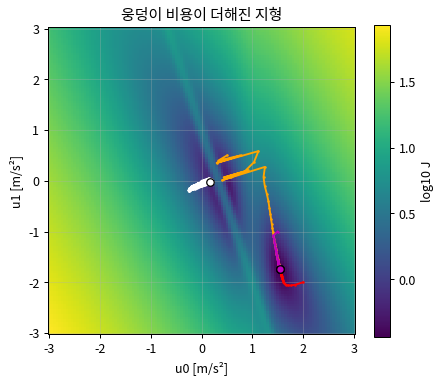

In [11]:
def J2_puddle(U, w_puddle=2.0, center=0.5, width=0.15):
    X = cart_rollout(x0, U, dt=1.0)
    p = X[..., 1:, 0]
    puddle = w_puddle * np.exp(-((p - center) / width) ** 2).sum(-1)    # 웅덩이 근처일수록 큼
    return J2(U) + puddle

J_pud = J2_puddle(np.stack([G0, G1], axis=-1))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
draw_landscape(ax, J_pud, '웅덩이 비용이 더해진 지형')
for start, col in [((0.0, 0.0), 'w'), ((2.0, -2.0), 'r'), ((0.5, 0.5), 'orange'), ((1.5, -1.0), 'm')]:
    U = np.array(start); path = [U.copy()]
    for it in range(500):
        U = U - 0.05 * numerical_grad(J2_puddle, U)
        path.append(U.copy())
    path = np.array(path)
    X = cart_rollout(x0, U, dt=1.0)
    ax.plot(path[:, 0], path[:, 1], '.-', ms=2, color=col)
    ax.plot(*U, 'o', color=col, mec='k')
    print('출발 %-12s → 도착 (%.2f, %.2f), J=%.3f, 위치 p1=%.2f p2=%.2f m' % (start, U[0], U[1], J2_puddle(U), X[1, 0], X[2, 0]))
plt.show()

**결과 해석:** 지형에 골짜기가 두 개 생겼다.
- (0, 0)에서 출발하면 2초 동안 0.25 m까지만 가서 웅덩이(0.5 m) 앞에 머무는 해에서 멈춘다. 비용은 약 0.71이다.
- 다른 출발점들은 웅덩이를 **빨리 지나가는** 해(1초째 0.77 m, 2초째 1.44 m)에 도착한다. 목표를 조금 지나치지만 비용이 약 0.37로 더 낮다.

(0, 0)에서 출발한 경사하강이 멈춘 곳은 **주변에서는 가장 낮지만 전체에서 가장 낮지는 않은** 곳이다. 이것을 **국소 최솟값**(local minimum)이라 하고, 전체에서 가장 낮은 곳을 **전역 최솟값**(global minimum)이라 한다. 경사하강은 발밑만 보기 때문에 어느 골짜기에 빠질지가 **출발점**에 달려 있다.

로봇에서는 이것이 "장애물 앞에서 멈춰 서서 돌아가지 못하는" 현상으로 나타난다. 06 노트에서 다시 만난다.

**직접 해보기:** 위 셀에서 `J2_puddle`의 웅덩이 세기 `w_puddle`을 2.0에서 0.5로 줄이거나 4.0으로 키워 (0, 0)에서 출발해 보자. 웅덩이가 약하면 지나갈까?
<details><summary>실행 결과</summary>

0.5로 약하게 해도 (0, 0) 출발은 여전히 웅덩이 앞에 멈춘다(2초째 위치 약 0.37 m). 4.0으로 키우면 더 일찍 멈춘다(약 0.18 m). 비용이 약해지면 골짜기가 얕아질 뿐, (0, 0)이 웅덩이 앞 골짜기 쪽에 있다는 사실은 그대로다. 어느 골짜기에 빠질지는 비용의 세기보다 **출발점**이 정한다.
</details>

## 8. 두 번째 한계 — 기울기가 0이라 안 보이는 비용

### 문제
웅덩이 비용이 종 모양처럼 매끄럽지 않고, "웅덩이 안(0.4~0.6 m)이면 비용 1, 밖이면 0"처럼 **딱 잘라져** 있다면?

### 아이디어
이런 비용은 웅덩이 안에서도 밖에서도 평평하다. 조금 움직여도 비용이 변하지 않으므로 **기울기가 0**이다. 경사하강은 이 비용이 있다는 사실조차 모른다.

In [12]:
def J2_hard_puddle(U, w_puddle=2.0):
    X = cart_rollout(x0, U, dt=1.0)
    p = X[..., 1:, 0]
    inside = (np.abs(p - 0.5) < 0.1)                     # 0.4~0.6 m 안이면 True
    return J2(U) + w_puddle * inside.sum(-1)

U = np.zeros(2)
for it in range(500):
    U = U - 0.05 * numerical_grad(J2_hard_puddle, U)
X = cart_rollout(x0, U, dt=1.0)
print('도착 U=(%.2f, %.2f), 1초째 위치 p1=%.2f m → 웅덩이 안: %s' % (U[0], U[1], X[1, 0], abs(X[1, 0] - 0.5) < 0.1))
print('그 점에서 웅덩이 비용의 기울기:', numerical_grad(lambda V: J2_hard_puddle(V) - J2(V), U))
print('전체 비용 J=%.3f 중 웅덩이 비용 %.0f' % (J2_hard_puddle(U), J2_hard_puddle(U) - J2(U)))

도착 U=(0.97, -0.95), 1초째 위치 p1=0.49 m → 웅덩이 안: True
그 점에서 웅덩이 비용의 기울기: [0. 0.]
전체 비용 J=2.019 중 웅덩이 비용 2


**결과 해석:** 경사하강은 웅덩이가 없을 때와 똑같이 (1, −1) 근처로 가고, 1초째 위치가 웅덩이 한가운데(0.5 m)다. 웅덩이 비용을 받고 있는데도 그 비용의 기울기가 0이라서 피할 방향을 알 수 없었다.

로봇의 충돌 비용도 비슷한 성질이 있다. 장애물에서 일정 거리 이상 떨어지면 비용이 **정확히 0**이다(06 노트의 activation distance). 멀리 있을 때는 기울기도 0이라 경사하강은 장애물을 보지 못한다.

**정리하면, 경사하강의 약점은 셋이다.**
1. 출발점에 따라 국소 최솟값에 갇힌다.
2. 평평하거나 딱 잘라진 비용은 기울기가 0이라 보지 못한다.
3. 반복을 **한 걸음씩 차례로** 해야 해서 나눠 계산하기 어렵다. 학습률도 잘 골라야 한다.

05 노트의 MPPI는 기울기를 쓰지 않는다. **비용 값만** 보고, 후보 수백 개를 **동시에** 평가해서 이 약점들을 피한다.

## 핵심 정리

- **최적화**: 비용 $J(U)$를 가장 작게 하는 $U^*$를 찾는 일. 입력이 2개면 비용 지형을 그림으로 볼 수 있다.
- **격자 탐색**은 입력 수가 늘면 계산이 곱으로 불어나 금방 불가능해진다(차원의 저주).
- **경사하강**: 수치 미분으로 기울기를 구하고 $U \leftarrow U - \alpha \nabla J$로 내려간다. 학습률이 작으면 느리고 크면 발산한다.
- 한계: 출발점에 따라 **국소 최솟값**에 갇히고, 기울기가 0인 비용은 보지 못한다.

## 확인 문제

<details><summary>1. 입력 7개 × 30스텝 로봇팔 문제를 한 축 3칸 격자로 탐색하면 몇 번 계산해야 하나?</summary>

$3^{210}$번(약 $10^{100}$). 불가능하다.
</details>

<details><summary>2. 경사하강에서 비용이 반복마다 오히려 커진다면 무엇을 의심해야 하나?</summary>

학습률이 너무 크다(발산). 줄여야 한다.
</details>

<details><summary>3. 출발점을 바꿨더니 결과가 달라졌다. 무슨 뜻인가?</summary>

비용 지형에 골짜기(국소 최솟값)가 여러 개 있고, 출발점에 따라 다른 골짜기로 내려갔다는 뜻이다.
</details>

<details><summary>4. 장애물에서 10 cm 이상 떨어지면 비용이 0인 충돌 비용을 경사하강으로 최적화한다. 로봇이 장애물에서 30 cm 떨어져 있을 때 장애물 쪽으로 가는 계획을 막을 수 있나?</summary>

지금 계획의 모든 시점이 10 cm 밖이라면 충돌 비용의 기울기가 0이라 막지 못한다. 계획이 10 cm 안으로 들어오는 시점이 생긴 뒤에야 밀어낸다.
</details>

## 실제 프로젝트에서는

cuRobo의 MPC 설정은 최적화 방법을 고를 수 있다. 경사 기반(L-BFGS)과 샘플링 기반(MPPI)이 둘 다 들어 있다. 이 프로젝트는 MPPI만 쓴다. `~/franka-depth-mppi/experiment/hand_experiment.py:100`의 `MpcSolverConfig.load_from_robot_config(..., use_mppi=True, use_lbfgs=False, use_es=False, ...)`가 그 설정이다. 그 이유가 이 노트의 8절과 05 노트에 있다.

## 다음 노트

[04 · MPC: 계획하고 한 발만](04_mpc.ipynb): 이제 최적의 계획을 찾을 수 있다. 하지만 01에서 봤듯이 실제 카트는 모델과 다르게 움직인다. 계획을 끝까지 따르지 않고 매 순간 다시 세우는 MPC를 배운다.